<a href="https://colab.research.google.com/github/Rogerio-mack/work/blob/main/cores_testes_de_signific%C3%A2ncia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Influência das cores em jogos digitais**

Análises realizadas:

- Percepção de Tempo
- Pontuação
- Imersão
- (SAM) Prazer
- Desconforto físico

Também avaliado para os grupos somente e homens e mulheres.



# Conclusão dos testes

Aqui os resultados de diferenças significativas ($\alpha = 0.05$):

| Grupo | Variável | Teste |	Q média	| F média	| Q mediana	| F mediana |	Dif média	|Estatística |	p-valor |	Quente != Frio |
|-|-|-|-|-|-|-|-|-|-|-|
|**Todos**| ssq_dor_cabeca	| Wilcoxon two-sided	|0.10	|0.02	|0.00	|0.00	|0.08|	0.00|	0.05|	True|
|**Feminino**|sam_ativacao|	Wilcoxon two-sided|	3.42|	2.96|	4.00|	3.00|	0.46|	22.00|	0.05|	True|

<br>

Para o grupo **Masculino** nenhuma diferença significativa. Todos os demais valores sem diferença significativa.



In [1]:
import pandas as pd
import numpy as numpy


In [2]:
data = pd.read_excel('/content/base_analise_mestrado.xlsx',sheet_name='Base_unificada')
data.head()

,Participante_ID,idade,genero,curso,semestre,frequencia_jogos,plataforma_principal,qualidade_sono,cafeina_2h,sam_prazer_pre,...,game_fria_duracao_s,game_fria_pontuacao,game_fria_vidas_restantes,game_fria_colisoes,game_fria_pulos,game_fria_agachamentos,game_fria_dificuldade_max_pct,game_fria_velocidade_max,game_fria_motivo_encerramento,game_fria_valida_metricas
0,LMH,27,Feminino,Análise e Desenvolvimento de Sistemas,5,Às vezes (1–2x/semana),Celular,Muito boa,Não,Muito agradável,...,180.02,1554,2,22,101,1,100,820,time-up,Sim
1,BAM,23,Feminino,Ciência da Computação,8,Às vezes (1–2x/semana),Celular,Regular,Sim,Muito agradável,...,180.01,1800,2,1,108,10,100,820,time-up,Sim
2,TGB,21,Masculino,Ciência da Computação,8,Às vezes (1–2x/semana),"Computador / Notebook, Console (PlayStation, X...",Boa,Não,Agradável,...,180.01,1800,3,0,108,10,100,820,time-up,Sim
3,ARC,21,Masculino,Sistemas de Informação,7,Frequentemente (3–5x/semana),Computador / Notebook,Boa,Sim,Muito agradável,...,180.01,1800,1,2,117,6,100,820,time-up,Sim
4,LASM,20,Masculino,Ciência da Computação,6,Às vezes (1–2x/semana),Computador / Notebook,Ruim,Não,Muito agradável,...,180.01,1790,2,4,113,2,100,820,time-up,Sim


## Grupos Masculino e Feminino

Para análise Grupos Masculino e Feminino, altere os comentários aqui e ao final (save results in .xlsx tables), reinicie a sessão e execute.

In [3]:
# data = data[ data.genero == 'Masculino' ]
# data = data[ data.genero == 'Feminino' ]


In [4]:
data.iloc[0]

,0
Participante_ID,LMH
idade,27
genero,Feminino
curso,Análise e Desenvolvimento de Sistemas
semestre,5
...,...
game_fria_agachamentos,1
game_fria_dificuldade_max_pct,100
game_fria_velocidade_max,820
game_fria_motivo_encerramento,time-up


# Análise Percepção de Tempo e Pontuação

Aplicado o **Wilcoxon Signed-Rank Test**, teste não paramétrico em substituição ao teste t pareado, uma vez que o pressuposto de normalidade aplicado às diferenças par a par ($D_i = \mu_A - \mu_B$) é violado.

No lugar de comparar as médias aritméticas, o teste de Wilcoxon avalia os postos (ranks) das diferenças pareadas, testando se a mediana das diferenças é igual a zero.


In [5]:
testes = {}

In [6]:
sel_cols = [x for x in data.columns if x.count('_pontuacao') > 0 or x.count('_tempo_estimado') > 0]
df = data[sel_cols].copy()
df.drop(columns='ishihara_pontuacao',inplace=True)
df.head()

,quente_tempo_estimado_s,fria_tempo_estimado_s,game_quente_pontuacao,game_fria_pontuacao
0,120,110,1701,1554
1,270,210,1800,1800
2,160,150,1800,1800
3,390,340,1800,1800
4,130,160,1793,1790


## Tempo estimado

In [7]:
from numpy._core.numeric import fromfunction
#@markdown `plot_distribuicoes(quente,frio,labelA,labelB,var)`
def plot_distribuicoes(quente,frio,labelA,labelB,var):
  import matplotlib.pyplot as plt
  import seaborn as sns
  import warnings
  warnings.filterwarnings('ignore')


  diferenca = quente - frio

  # Exemplo
  # A = df['quente_tempo_estimado_s']
  # B = df['fria_tempo_estimado_s']
  # labelA = 'quente'
  # labelB = 'frio'
  # var = 'tempo estimado'
  #
  # plot_distribuicoes(A,B,labelA,labelB,var)

  A = quente
  B = frio

  title = f'Distribuição de {var}'
  plt.figure(figsize=(10, 4))
  plt.subplot(1, 2, 1)
  sns.boxplot(data=[A, B],color="white")
  sns.swarmplot(data=[A,B],color="black")
  plt.xticks([0,1],[labelA,labelB])
  plt.xlabel('tela quente x fria')
  plt.ylabel(var)
  # plt.title(title)
  # plt.legend()

  plt.subplot(1, 2, 2)
  sns.histplot(A, bins=15, kde=True, color='blue', label=labelA, alpha=0.3)
  sns.histplot(B, bins=15, kde=True, color='green', label=labelB, alpha=0.3)
  plt.xlabel(var)
  plt.ylabel('frequência')
  # plt.title(title)
  plt.legend()

  plt.suptitle(title)

  plt.tight_layout()
  plt.show()

    # Estatísticas descritivas básicas
  print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
  for i, x in enumerate([quente,frio]):
    print(f"{['Quente','Frio  '][i]} Média: {x.mean():.2f} Mediana: {x.median():.2f} std: {x.std():.2f} (min, max): {x.min():.2f}, {x.max():.2f}")
  print(f"Diferença Média (Quente - Fria): {diferenca.mean():.2f}")
  return

In [8]:
#@markdown `def testes_t_wilcoxon(quente,frio,alternative='two-sided')`
def testes_t_wilcoxon(quente,frio,alternative='two-sided'):
  import scipy.stats as stats

  # Exemplo
  # quente = df['game_quente_pontuacao']
  # fria = df['game_fria_pontuacao']
  # alternative='two-sided' # or 'greater', quente > frio
  # testes_t_wilcoxon(quente,frio,alternative='two-sided')

  diferenca = quente - frio

  # Estatísticas descritivas básicas
  print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
  for i, x in enumerate([quente,frio]):
    print(f"{['Quente','Frio  '][i]} Média: {x.mean():.2f} Mediana: {x.median():.2f} std: {x.std():.2f} (min, max): {x.min():.2f}, {x.max():.2f}")
  print(f"Diferença Média (Quente - Fria): {diferenca.mean():.2f}")
  print()

  # 1. Teste de Normalidade de Shapiro-Wilk na diferença
  shapiro_stat, shapiro_p = stats.shapiro(diferenca)

  print("=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===")
  print(f"Estatística: {shapiro_stat:.4f}")
  print(f"p-valor: {shapiro_p:.4f}")

  # Escolha do teste com base na normalidade (alfa = 0.05)
  if shapiro_p > 0.05:
      # Dados normais -> Teste t pareado (alternativa: 'greater' para verificar se quente > fria)
      test_name = f"t Pareado {alternative}"
      stat, p_val = stats.ttest_rel(quente, frio, alternative=alternative)
  else:
      # Dados não normais -> Teste de Wilcoxon (alternativa: 'greater')
      test_name = f"Wilcoxon {alternative}"
      stat, p_val = stats.wilcoxon(quente, frio, alternative=alternative)

  # 2. Apresentação dos resultados do teste de hipótese
  print(f"\n=== TESTE DE HIPÓTESE: {test_name} ===")
  print(f"Estatística do teste: {stat:.4f}")
  print(f"p-valor: {p_val:.4f}")

  # 3. Conclusão prática
  print("\n=== CONCLUSÃO ===")
  alfa = 0.05
  if p_val < alfa:
      print(f"p-valor ({p_val:.4f}) < {alfa}, REJEITAMOS a hipótese nula (H0).")
      print(f"Há evidências estatísticas significativas de que A { {'two-sided':'!=','greater':'>','less':'<'}[alternative] } B.")
  else:
      print(f"p-valor ({p_val:.4f}) <= {alfa}, NÃO REJEITAMOS a hipótese nula (H0).")
      print(f"Não há evidências estatísticas suficientes para afirmar que A { {'two-sided':'!=','greater':'>','less':'<'}[alternative] } B.")

  print()
  return test_name,quente.mean(),frio.mean(),quente.median(),frio.median(),diferenca.mean(),stat,p_val

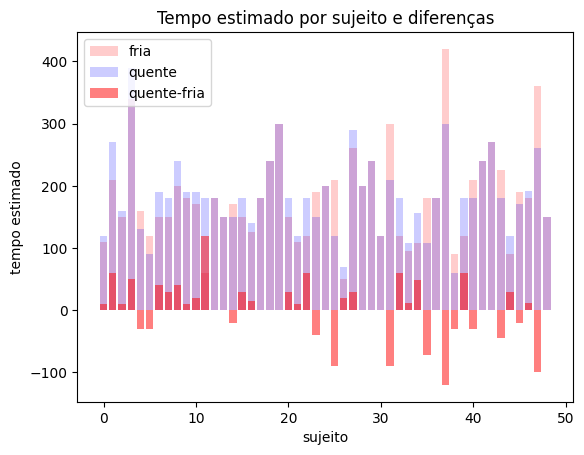

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.bar(x=range(0,len(df['fria_tempo_estimado_s'])),height=df['fria_tempo_estimado_s'],alpha=0.2,color='r',label='fria')
plt.bar(x=range(0,len(df['quente_tempo_estimado_s'])),height=df['quente_tempo_estimado_s'],alpha=0.2,color='b',label='quente')
plt.bar(x=range(0,len(df['quente_tempo_estimado_s'])),height=df['quente_tempo_estimado_s']-df['fria_tempo_estimado_s'],alpha=0.5,color='r',label='quente-fria')
plt.legend(loc='upper left')
plt.title('Tempo estimado por sujeito e diferenças')
plt.xlabel('sujeito')
plt.ylabel('tempo estimado')
plt.show()

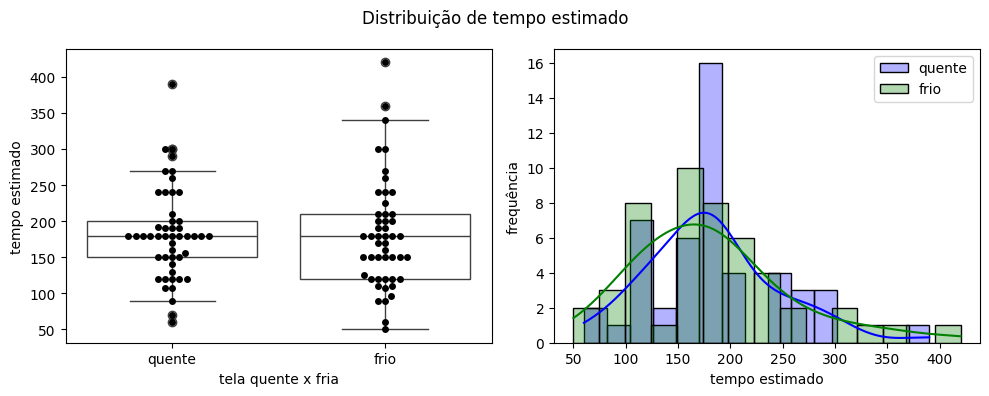


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 182.94 Mediana: 180.00 std: 63.81 (min, max): 60.00, 390.00
Frio   Média: 181.10 Mediana: 180.00 std: 75.45 (min, max): 50.00, 420.00
Diferença Média (Quente - Fria): 1.84


In [10]:
quente = df['quente_tempo_estimado_s']
frio = df['fria_tempo_estimado_s']

plot_distribuicoes(quente,frio,'quente','frio','tempo estimado')

In [11]:
results = testes_t_wilcoxon(quente,frio,alternative='two-sided')

testes['tempo_estimado'] = results


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 182.94 Mediana: 180.00 std: 63.81 (min, max): 60.00, 390.00
Frio   Média: 181.10 Mediana: 180.00 std: 75.45 (min, max): 50.00, 420.00
Diferença Média (Quente - Fria): 1.84

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.9378
p-valor: 0.0122

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 294.5000
p-valor: 0.5443

=== CONCLUSÃO ===
p-valor (0.5443) <= 0.05, NÃO REJEITAMOS a hipótese nula (H0).
Não há evidências estatísticas suficientes para afirmar que A != B.



## Pontuação

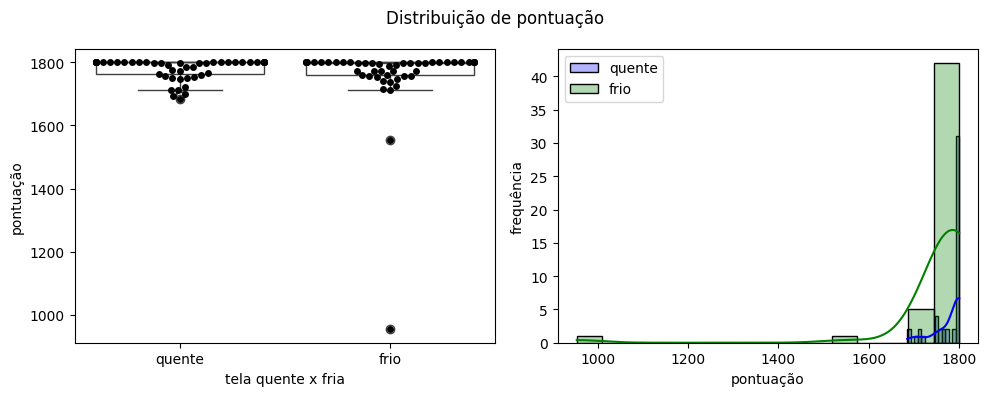


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 1779.20 Mediana: 1800.00 std: 33.01 (min, max): 1685.00, 1800.00
Frio   Média: 1760.49 Mediana: 1799.00 std: 124.61 (min, max): 954.00, 1800.00
Diferença Média (Quente - Fria): 18.71


In [12]:
quente = df['game_quente_pontuacao']
frio = df['game_fria_pontuacao']

plot_distribuicoes(quente,frio,'quente','frio','pontuação')

In [13]:
results = testes_t_wilcoxon(quente,frio,alternative='two-sided')

testes['pontuação'] = results


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 1779.20 Mediana: 1800.00 std: 33.01 (min, max): 1685.00, 1800.00
Frio   Média: 1760.49 Mediana: 1799.00 std: 124.61 (min, max): 954.00, 1800.00
Diferença Média (Quente - Fria): 18.71

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.3412
p-valor: 0.0000

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 230.0000
p-valor: 0.7242

=== CONCLUSÃO ===
p-valor (0.7242) <= 0.05, NÃO REJEITAMOS a hipótese nula (H0).
Não há evidências estatísticas suficientes para afirmar que A != B.



In [14]:
df_testes = pd.DataFrame(testes).T
df_testes.columns = ['Teste','Q média','F média','Q mediana','F mediana','Dif média','Estatística','p-valor']
df_testes['Quente != Frio'] = df_testes['p-valor'] < 0.05
df_testes

,Teste,Q média,F média,Q mediana,F mediana,Dif média,Estatística,p-valor,Quente != Frio
tempo_estimado,Wilcoxon two-sided,182.938776,181.102041,180.0,180.0,1.836735,294.5,0.544297,False
pontuação,Wilcoxon two-sided,1779.204082,1760.489796,1800.0,1799.0,18.714286,230.0,0.724222,False


# Imersão

Aqui também é aplicado o **Wilcoxon Signed-Rank Test**, teste não paramétrico. A escala Likert produz dados ordinais, o teste de Wilcoxon neste caso é o padrão, pois opera sobre a ordenação dos postos (ranks) das respostas, evitando assumir continuidade ou distribuição normal dos dados.


In [15]:
sel_cols = [x for x in data.columns if x.count('_flow_') > 0 and x[-2::] == '_n' and x.count('quente') > 0]
df_quente = data[sel_cols].copy()
display(df_quente.head())

sel_cols = [x for x in data.columns if x.count('_flow_') > 0 and x[-2::] == '_n' and x.count('fria') > 0]
df_frio = data[sel_cols].copy()
display(df_frio.head())

,quente_flow_concentracao_n,quente_flow_naturalidade_n,quente_flow_envolvimento_n,quente_flow_perda_nocao_tempo_n,quente_flow_controle_n,quente_flow_imersao_n
0,5,5,5,5,5,5
1,5,5,5,2,5,5
2,3,4,4,2,4,4
3,5,4,4,5,3,4
4,4,4,4,4,4,4


,fria_flow_concentracao_n,fria_flow_naturalidade_n,fria_flow_envolvimento_n,fria_flow_perda_nocao_tempo_n,fria_flow_controle_n,fria_flow_imersao_n
0,5,5,5,5,5,5
1,5,5,5,2,5,5
2,4,4,4,2,4,4
3,4,3,3,4,4,4
4,2,4,2,3,4,3


In [16]:
for quente in df_quente.columns:
  frio = quente.replace('quente','fria')
  results = testes_t_wilcoxon(df_quente[quente],df_frio[frio],alternative='two-sided')
  testes[quente.replace('quente_','').replace('_n','')] = results



=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 4.24 Mediana: 4.00 std: 0.80 (min, max): 2.00, 5.00
Frio   Média: 4.12 Mediana: 4.00 std: 0.97 (min, max): 1.00, 5.00
Diferença Média (Quente - Fria): 0.12

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.8407
p-valor: 0.0000

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 126.0000
p-valor: 0.2945

=== CONCLUSÃO ===
p-valor (0.2945) <= 0.05, NÃO REJEITAMOS a hipótese nula (H0).
Não há evidências estatísticas suficientes para afirmar que A != B.


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 4.29 Mediana: 4.00 std: 0.76 (min, max): 2.00, 5.00
Frio   Média: 4.29 Mediana: 4.00 std: 0.84 (min, max): 2.00, 5.00
Diferença Média (Quente - Fria): 0.00

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.8251
p-valor: 0.0000

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 94.5000
p-valor: 0.9831

=== CONCLUSÃO ===
p-valor (0.9831) <= 0.05, NÃO REJEITAMOS a 

In [17]:
df_testes = pd.DataFrame(testes).T
df_testes.columns = ['Teste','Q média','F média','Q mediana','F mediana','Dif média','Estatística','p-valor']
df_testes['Quente != Frio'] = df_testes['p-valor'] < 0.05
df_testes

,Teste,Q média,F média,Q mediana,F mediana,Dif média,Estatística,p-valor,Quente != Frio
tempo_estimado,Wilcoxon two-sided,182.938776,181.102041,180.0,180.0,1.836735,294.5,0.544297,False
pontuação,Wilcoxon two-sided,1779.204082,1760.489796,1800.0,1799.0,18.714286,230.0,0.724222,False
flow_concentracao,Wilcoxon two-sided,4.244898,4.122449,4.0,4.0,0.122449,126.0,0.294538,False
flowaturalidade,Wilcoxon two-sided,4.285714,4.285714,4.0,4.0,0.0,94.5,0.983143,False
flow_envolvimento,Wilcoxon two-sided,4.244898,4.020408,4.0,4.0,0.22449,90.0,0.117104,False
flow_perdaocao_tempo,Wilcoxon two-sided,3.408163,3.530612,3.0,3.0,-0.122449,157.5,0.432084,False
flow_controle,Wilcoxon two-sided,4.183673,4.326531,4.0,4.0,-0.142857,45.0,0.196512,False
flow_imersao,Wilcoxon two-sided,4.142857,4.122449,4.0,4.0,0.020408,76.0,0.979781,False


# SAM Prazer, ativação e dominância

Aqui também é aplicado o **Wilcoxon Signed-Rank Test**.


In [18]:
sel_cols = [x for x in data.columns if x.count('_sam_') > 0 and x[-2::] == '_n' and x.count('quente') > 0]
df_quente = data[sel_cols].copy()
display(df_quente.head())

sel_cols = [x for x in data.columns if x.count('_sam_') > 0 and x[-2::] == '_n' and x.count('fria') > 0]
df_frio = data[sel_cols].copy()
display(df_frio.head())

,quente_sam_prazer_n,quente_sam_ativacao_n,quente_sam_dominancia_n
0,5,1,5
1,5,4,5
2,3,3,4
3,4,4,4
4,5,4,4


,fria_sam_prazer_n,fria_sam_ativacao_n,fria_sam_dominancia_n
0,5,1,5
1,5,4,5
2,3,3,5
3,3,3,4
4,4,2,3


In [19]:
for quente in df_quente.columns:
  frio = quente.replace('quente','fria')
  results = testes_t_wilcoxon(df_quente[quente],df_frio[frio],alternative='two-sided')
  testes[quente.replace('quente_','').replace('_n','')] = results


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 3.84 Mediana: 4.00 std: 0.80 (min, max): 2.00, 5.00
Frio   Média: 3.84 Mediana: 4.00 std: 0.69 (min, max): 2.00, 5.00
Diferença Média (Quente - Fria): 0.00

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.8682
p-valor: 0.0001

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 134.0000
p-valor: 0.8961

=== CONCLUSÃO ===
p-valor (0.8961) <= 0.05, NÃO REJEITAMOS a hipótese nula (H0).
Não há evidências estatísticas suficientes para afirmar que A != B.


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 3.35 Mediana: 4.00 std: 1.01 (min, max): 1.00, 5.00
Frio   Média: 3.10 Mediana: 3.00 std: 0.96 (min, max): 1.00, 5.00
Diferença Média (Quente - Fria): 0.24

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.9064
p-valor: 0.0009

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 115.0000
p-valor: 0.1106

=== CONCLUSÃO ===
p-valor (0.1106) <= 0.05, NÃO REJEITAMOS a

In [20]:
df_testes = pd.DataFrame(testes).T
df_testes.columns = ['Teste','Q média','F média','Q mediana','F mediana','Dif média','Estatística','p-valor']
df_testes['Quente != Frio'] = df_testes['p-valor'] < 0.05
df_testes

,Teste,Q média,F média,Q mediana,F mediana,Dif média,Estatística,p-valor,Quente != Frio
tempo_estimado,Wilcoxon two-sided,182.938776,181.102041,180.0,180.0,1.836735,294.5,0.544297,False
pontuação,Wilcoxon two-sided,1779.204082,1760.489796,1800.0,1799.0,18.714286,230.0,0.724222,False
flow_concentracao,Wilcoxon two-sided,4.244898,4.122449,4.0,4.0,0.122449,126.0,0.294538,False
flowaturalidade,Wilcoxon two-sided,4.285714,4.285714,4.0,4.0,0.0,94.5,0.983143,False
flow_envolvimento,Wilcoxon two-sided,4.244898,4.020408,4.0,4.0,0.22449,90.0,0.117104,False
flow_perdaocao_tempo,Wilcoxon two-sided,3.408163,3.530612,3.0,3.0,-0.122449,157.5,0.432084,False
flow_controle,Wilcoxon two-sided,4.183673,4.326531,4.0,4.0,-0.142857,45.0,0.196512,False
flow_imersao,Wilcoxon two-sided,4.142857,4.122449,4.0,4.0,0.020408,76.0,0.979781,False
sam_prazer,Wilcoxon two-sided,3.836735,3.836735,4.0,4.0,0.0,134.0,0.896088,False
sam_ativacao,Wilcoxon two-sided,3.346939,3.102041,4.0,3.0,0.244898,115.0,0.110587,False


# Desconforto físico (SSQ)

O **Wilcoxon Signed-Rank Test** também será o empregado para uma escala de apenas 3 valores ordinais.

Dados de '*_ssq_nausea' excluídos da análise. Todos respondentes com 0 para quente e frio.


In [21]:
sel_cols = [x for x in data.columns if x.count('_ssq_') > 0 and x[-2::] == '_n' and x.count('quente') > 0]
df_quente = data[sel_cols].copy()
display(df_quente.head())

sel_cols = [x for x in data.columns if x.count('_ssq_') > 0 and x[-2::] == '_n' and x.count('fria') > 0]
df_frio = data[sel_cols].copy()
display(df_frio.head())

,quente_ssq_nausea_n,quente_ssq_suor_n,quente_ssq_dor_cabeca_n,quente_ssq_cansaco_visual_n,quente_ssq_fadiga_n,quente_ssq_desorientacao_n
0,0,0,0,0,0,0
1,0,0,0,2,0,0
2,0,0,0,0,0,0
3,0,0,0,1,0,0
4,0,0,0,0,0,0


,fria_ssq_nausea_n,fria_ssq_suor_n,fria_ssq_dor_cabeca_n,fria_ssq_cansaco_visual_n,fria_ssq_fadiga_n,fria_ssq_desorientacao_n
0,0,0,0,0,0,0
1,0,0,0,1,0,0
2,0,0,0,0,0,0
3,0,0,0,1,0,0
4,0,0,0,0,0,0


In [22]:
df_quente['quente_ssq_nausea_n'].value_counts(), df_frio['fria_ssq_nausea_n'].value_counts()

(quente_ssq_nausea_n
 0    49
 Name: count, dtype: int64,
 fria_ssq_nausea_n
 0    49
 Name: count, dtype: int64)

In [23]:
df_quente.drop(columns='quente_ssq_nausea_n',inplace=True)
df_frio.drop(columns='fria_ssq_nausea_n',inplace=True)

In [24]:
for quente in df_quente.columns:
  frio = quente.replace('quente','fria')
  results = testes_t_wilcoxon(df_quente[quente],df_frio[frio],alternative='two-sided')
  testes[quente.replace('quente_','').replace('_n','')] = results


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 0.06 Mediana: 0.00 std: 0.24 (min, max): 0.00, 1.00
Frio   Média: 0.04 Mediana: 0.00 std: 0.20 (min, max): 0.00, 1.00
Diferença Média (Quente - Fria): 0.02

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.1273
p-valor: 0.0000

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 0.0000
p-valor: 0.3173

=== CONCLUSÃO ===
p-valor (0.3173) <= 0.05, NÃO REJEITAMOS a hipótese nula (H0).
Não há evidências estatísticas suficientes para afirmar que A != B.


=== ESTATÍSTICAS DESCRITIVAS ===
Quente Média: 0.10 Mediana: 0.00 std: 0.31 (min, max): 0.00, 1.00
Frio   Média: 0.02 Mediana: 0.00 std: 0.14 (min, max): 0.00, 1.00
Diferença Média (Quente - Fria): 0.08

=== TESTE DE NORMALIDADE (Shapiro-Wilk nas diferenças) ===
Estatística: 0.3062
p-valor: 0.0000

=== TESTE DE HIPÓTESE: Wilcoxon two-sided ===
Estatística do teste: 0.0000
p-valor: 0.0455

=== CONCLUSÃO ===
p-valor (0.0455) < 0.05, REJEITAMOS a hipótese

In [25]:
df_testes = pd.DataFrame(testes).T
df_testes.columns = ['Teste','Q média','F média','Q mediana','F mediana','Dif média','Estatística','p-valor']
df_testes['Quente != Frio'] = df_testes['p-valor'] < 0.05
df_testes

,Teste,Q média,F média,Q mediana,F mediana,Dif média,Estatística,p-valor,Quente != Frio
tempo_estimado,Wilcoxon two-sided,182.938776,181.102041,180.0,180.0,1.836735,294.5,0.544297,False
pontuação,Wilcoxon two-sided,1779.204082,1760.489796,1800.0,1799.0,18.714286,230.0,0.724222,False
flow_concentracao,Wilcoxon two-sided,4.244898,4.122449,4.0,4.0,0.122449,126.0,0.294538,False
flowaturalidade,Wilcoxon two-sided,4.285714,4.285714,4.0,4.0,0.0,94.5,0.983143,False
flow_envolvimento,Wilcoxon two-sided,4.244898,4.020408,4.0,4.0,0.22449,90.0,0.117104,False
flow_perdaocao_tempo,Wilcoxon two-sided,3.408163,3.530612,3.0,3.0,-0.122449,157.5,0.432084,False
flow_controle,Wilcoxon two-sided,4.183673,4.326531,4.0,4.0,-0.142857,45.0,0.196512,False
flow_imersao,Wilcoxon two-sided,4.142857,4.122449,4.0,4.0,0.020408,76.0,0.979781,False
sam_prazer,Wilcoxon two-sided,3.836735,3.836735,4.0,4.0,0.0,134.0,0.896088,False
sam_ativacao,Wilcoxon two-sided,3.346939,3.102041,4.0,3.0,0.244898,115.0,0.110587,False


# Todos os resultados

In [26]:
display(df_testes.style.format(precision=2))

,Teste,Q média,F média,Q mediana,F mediana,Dif média,Estatística,p-valor,Quente != Frio
tempo_estimado,Wilcoxon two-sided,182.94,181.10,180.00,180.00,1.84,294.50,0.54,False
pontuação,Wilcoxon two-sided,1779.20,1760.49,1800.00,1799.00,18.71,230.00,0.72,False
flow_concentracao,Wilcoxon two-sided,4.24,4.12,4.00,4.00,0.12,126.00,0.29,False
flowaturalidade,Wilcoxon two-sided,4.29,4.29,4.00,4.00,0.00,94.50,0.98,False
flow_envolvimento,Wilcoxon two-sided,4.24,4.02,4.00,4.00,0.22,90.00,0.12,False
flow_perdaocao_tempo,Wilcoxon two-sided,3.41,3.53,3.00,3.00,-0.12,157.50,0.43,False
flow_controle,Wilcoxon two-sided,4.18,4.33,4.00,4.00,-0.14,45.00,0.20,False
flow_imersao,Wilcoxon two-sided,4.14,4.12,4.00,4.00,0.02,76.00,0.98,False
sam_prazer,Wilcoxon two-sided,3.84,3.84,4.00,4.00,0.00,134.00,0.90,False
sam_ativacao,Wilcoxon two-sided,3.35,3.10,4.00,3.00,0.24,115.00,0.11,False


In [27]:
df_testes.to_excel('results_all.xlsx') # all
# df_testes.to_excel('results_masculino.xlsx')
# df_testes.to_excel('results_feminino.xlsx')